# Ajuste de parametros

In [1286]:
! cd ../Code && make clean && make > /dev/null && ./run.x > /dev/null

rm -f *.x *.o *.mod *.dat *.bin *.log *~
rm -f -rf 


In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d
from matplotlib.patches import Ellipse

In [1263]:
import subprocess
def iniciar_pruebas(line_to_find = '   real(dp) :: z0 = 150d0*R_g', new_line = '''   real(dp) :: z0 = 250d0*R_g                    !Jet launching height
''' ):
    # === CONFIGURATION ===
    file_path = '../Code/system_parameters/system_parameters_CenA.f90'        # path to your Fortran file
    line_to_find = '   real(dp) :: z0 = 150d0*R_g'  # text in line to search for
    new_line = '''   real(dp) :: z0 = 250d0*R_g                    !Jet launching height
'''  # new content
    
#     line_to_find = '   real(dp), parameter :: zmax_inj = 0.5d3*R_g'  # text in line to search for
#     new_line = '''   real(dp), parameter :: zmax_inj = 0.5d4*R_g          !Jet maximum cell of injection
# '''  # new content
    # === STEP 1: Read and modify the file ===
    with open(file_path, 'r') as file:
        lines = file.readlines()
    for i, line in enumerate(lines):
        if line_to_find in line:
            print(f"Old line: {lines[i].strip()}")
            lines[i] = new_line
            print(f"New line: {lines[i].strip()}")
            break
    else:
        raise ValueError(f"Line containing '{line_to_find}' not found.")
    
    # === STEP 2: Write changes back to the file ===
    with open(file_path, 'w') as file:
        file.writelines(lines)
    
    ! cd ../Code && make clean && make
    ! cd ../Code && ./run.x

In [1264]:
# iniciar_pruebas()

# Constantes

In [46]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

In [47]:
M_BH = 5.5e7 #             !Black hole mass [Msun]
R_g = 1.477e5*M_BH

h = 6.6260755e-27
k_B = 1.380658e-16
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

# Funciones utiles

In [1267]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

In [1268]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["frequency", "emisivity", "absorption", "z_value"])
    
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["frequency"] - nu*1e9/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["frequency", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

In [1269]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

In [1270]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

In [1271]:
def Omega_beam(theta1, theta2):
    '''Beam solid angle in terms of the theta_HPBW (theta1 x theta2)
    Use the equation here: https://science.nrao.edu/facilities/vla/proposing/TBconv'''
    return np.pi * theta1 * theta2 / (4 * np.log(2))

def brightness_temperature(I, nu_hz):
    """
    Calculate the brightness temperature for a given intensity and frequency.

    Parameters:
    I (float or numpy.ndarray): Specific intensity [mJy].
    nu (float): Frequency [GHz].

    Returns:
    float or numpy.ndarray: Brightness temperature [K].
    """
    nu_hz *= 1e9 # Convert GHz to Hz
    

    return I/Omega_beam(0.0168*1e-3,0.0259*1e-3)#(c**2 * I) / (2 * k_B * nu_hz**2*Omega_beam(np.deg2rad(23 * 1e-3 / 3600),np.deg2rad(45 * 1e-3 / 3600))) #[K]

In [1272]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    r_avg=0.5*(np.exp(r_out_interp(safe_log(z_value)))+np.exp(r_in_interp(safe_log(z_value))))
    tau_avg=crossed_length(r_avg, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau)) #(1+tau)# opt thin #[erg/cm^2/s/erg/sr]
    

    return intensity_result, tau_avg #[erg/cm^2/s/Hz/sr]



# Carga de datos

In [1273]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
#x = np.linspace(-r_out.max(), r_out.max(), 200)
# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
I_45 = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
tau_avg_45= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value) #[erg/cm^2/s/Hz/sr]

/tmp/ipykernel_3786/1369176478.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["frequency", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_3786/1249581915.py:23: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [1274]:
I.max()*1e26

np.float64(3.195683991969896e+22)

In [1275]:
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

In [1276]:
from numba import njit, prange

def Convolve_map(x_map, y_map, F_map, sigma_x, sigma_y):
    y_min_c = y_map[0] - 5. * sigma_y
    y_max_c = y_map[-1] + 5. * sigma_y
    x_min_c = x_map[0] - 4. * sigma_x
    x_max_c = x_map[-1] + 4. * sigma_x
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c

    Dx_c = f_Ny * sigma_x
    Dy_c = f_Ny * sigma_y

    Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
    Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

    F_map = F_map * Dx_c_rad * Dy_c_rad

    Nx_c = int(ancho_x / Dx_c)
    Ny_c = int(ancho_y / Dy_c)

    x_c = np.linspace(x_min_c, x_max_c, Nx_c)
    y_c = np.linspace(y_min_c, y_max_c, Ny_c)

    x_double = np.tile(x_map[:, None], (1, len(y_map)))
    y_double = np.tile(y_map[None, :], (len(x_map), 1))

    print('Numero de celdas del mapa convolucionado:')
    print(Nx_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    @njit(parallel=True)
    def compute_F_map_c(x_c, y_c, x_double, y_double, F_map, sigma_x, sigma_y):
        Nx_c = len(x_c)
        Ny_c = len(y_c)
        F_map_c = np.ones((Nx_c, Ny_c))
        w_x = 0.5 / sigma_x ** 2
        w_y = 0.5 / sigma_y ** 2
        for i in prange(Nx_c):
            for j in prange(Ny_c):
                gaussian = np.exp(-(np.square(x_double - x_c[i]) * w_x + np.square(y_double - y_c[j]) * w_y))
                F_map_c[i, j] = np.sum(F_map * gaussian)
        return F_map_c

    F_map_c = compute_F_map_c(x_c, y_c, x_double, y_double, F_map, sigma_x, sigma_y)

    S_pre = np.sum(F_map)
    A_beam = 2 * np.pi * sigma_x * sigma_y
    A_cell = Dx_c * Dy_c
    mJy_beam = A_cell / A_beam
    S_post = np.sum(F_map_c) * mJy_beam

    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post / S_pre))

    return x_c, y_c, F_map_c


In [1277]:
! @start_time=$$(date +%s);
FWHM_x, FWHM_y= 0.0168, 0.0259 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 
X_c, Y_c, I_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I.T*1e26, sigma_x, sigma_y)
! end_time=$$(date +%s); \
	elapsed=$$((end_time - start_time)); \
	echo "Execution time: $${elapsed} s"

/bin/bash: -c: línea 1: error sintáctico cerca del elemento inesperado `date'
/bin/bash: -c: línea 1: ` @start_time=$$(date +%s);'
Numero de celdas del mapa convolucionado:
258 1981
Dimension of the convolution grid: 258x1981
Pre-conv: S(GHz) = 198.24206968984709 mJy
Post-conv: S(GHz) = 197.29274910202076 mJy
post/pre = 0.9952113061101937
/bin/bash: -c: línea 1: error sintáctico cerca del elemento inesperado `('
/bin/bash: -c: línea 1: ` end_time=$$(date +%s);  	elapsed=$$((end_time - start_time));  	echo "Execution time: $${elapsed} s"'


In [1278]:
print(I_c.shape)

(258, 1981)


In [1279]:
T_brillo=brightness_temperature(I_c, 230.0)
T_b=T_brillo
#T_b_45=brightness_temperature(I_c, 210.0)
T_b.max()/1e9

np.float64(42.60494000505298)

In [1280]:
obs_data = pd.read_csv('./EHT_OBS(TBvZ).csv')
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_TB = obs_data.iloc[:, 1].to_numpy()
obs_data2 = pd.read_csv('./EHT_OBS(TBvZ)2.csv')
obs_z2 = obs_data2.iloc[:, 0].to_numpy()
obs_TB2 = obs_data2.iloc[:, 1].to_numpy()


In [1281]:

# Take the highest value along the X_c axis for each Y_c (i.e., max over rows)
T_b_df = pd.DataFrame(T_b/1e9, index=X_c, columns=Y_c)
T_b_df_plus=T_b_df[T_b_df.index > 0] #Promedio con valores de x positivos
T_b_df_minus=T_b_df[T_b_df.index < 0] #Promedio con valores de x positivos
# T_b_mean_values = T_b_df_plus.mean(axis=0)
# T_b_mean_values_minus = T_b_df_minus.mean(axis=0)
T_b_mean_values = T_b_df_plus.max(axis=0)
T_b_mean_values_minus = T_b_df_minus.max(axis=0)

# El Grafico

/tmp/ipykernel_3786/4022432059.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(tick_labels)


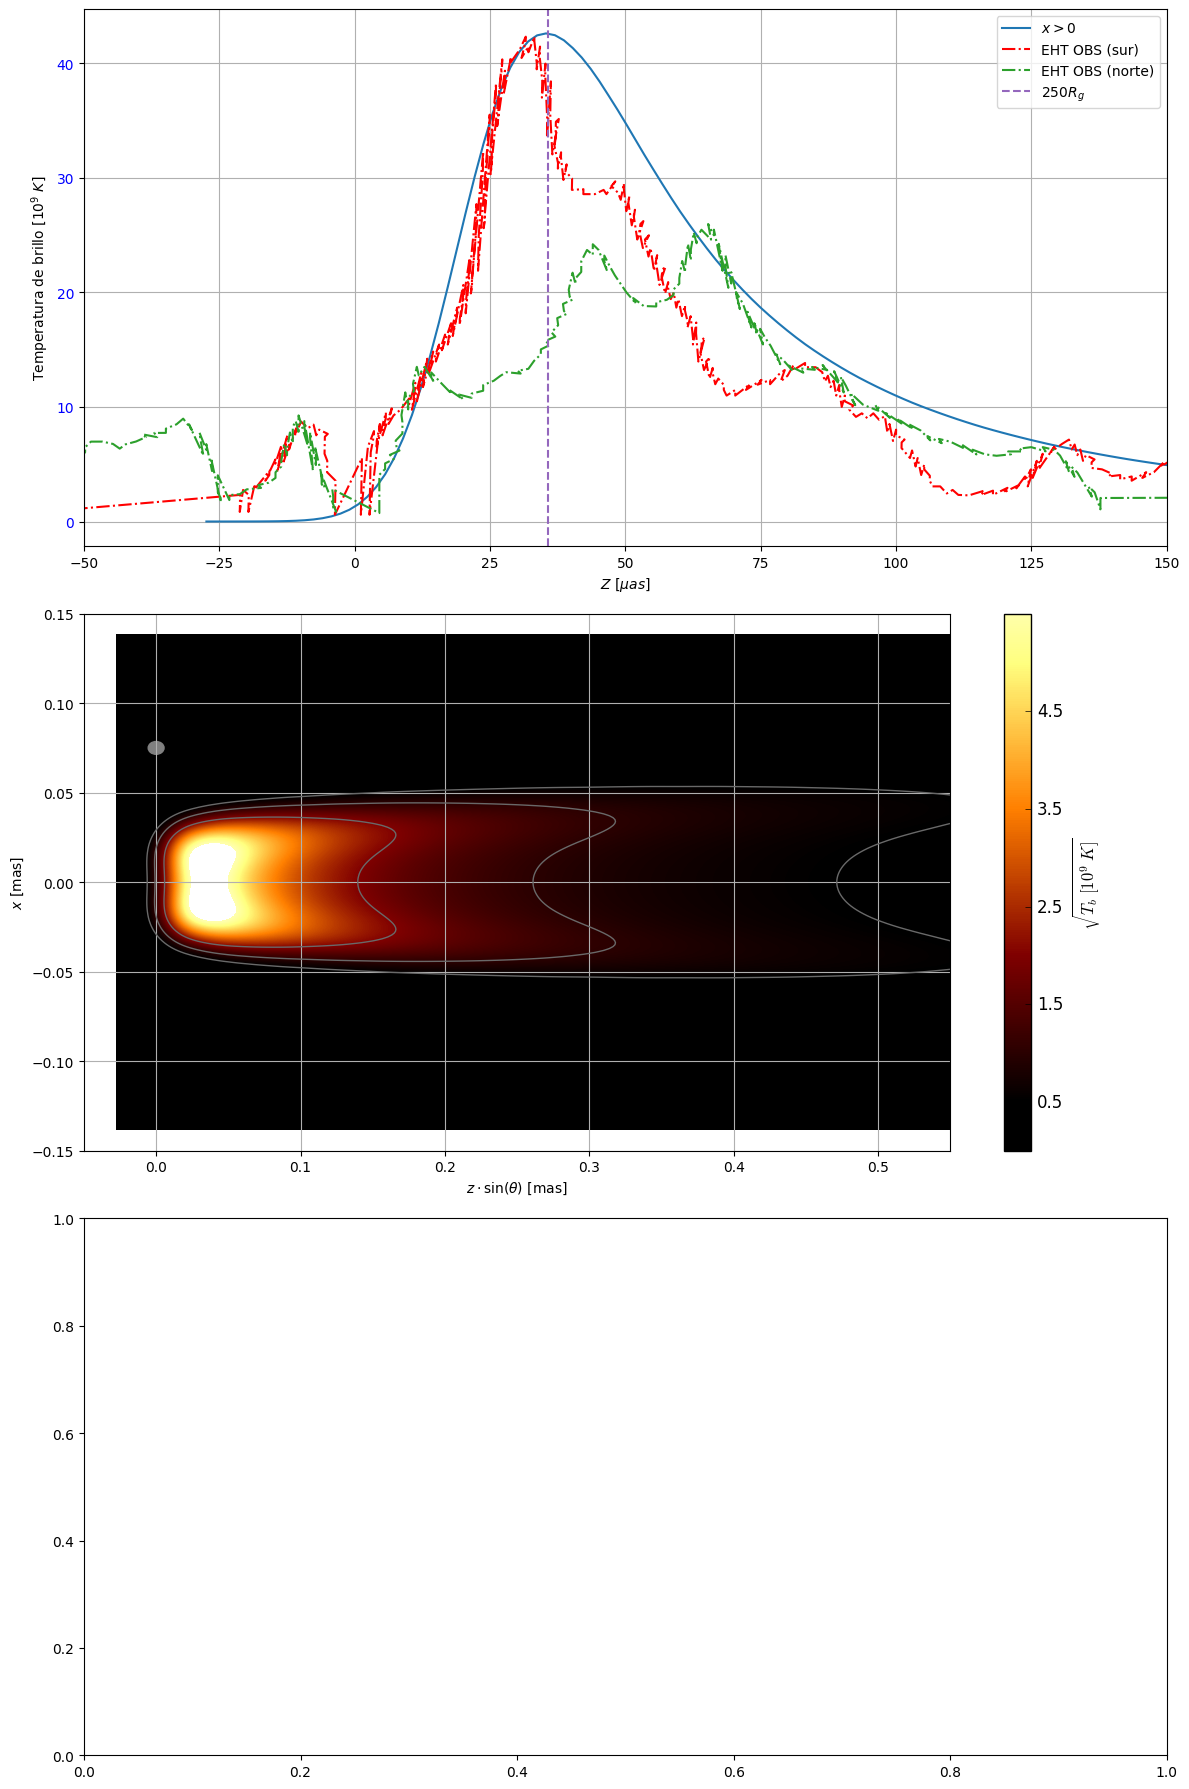

In [1282]:
fig, axs = plt.subplots(3, 1, figsize=(12, 18))

# --- T_B vs Z ---
axs[0].plot(Y_c*1e3, T_b_mean_values, label='$x>0$')
#axs[0].plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
axs[0].plot(obs_z, obs_TB, color='red', label='EHT OBS (sur)', linestyle='-.')
axs[0].plot(obs_z2, -obs_TB2, color='C2', label='EHT OBS (norte)', linestyle='-.')
axs[0].axvline(x=250*R_g*convert*1e3, color='C4', linestyle='--', label='$250R_g$')
axs[0].set_xlabel(fr'$Z~[\mu as]$')
axs[0].set_ylabel(r'Temperatura de brillo $[10^9~K]$')
axs[0].set_xlim(-50, 150)
axs[0].legend()
axs[0].grid()


# Set y-ticks to absolute values and color positive as blue, negative as orange
y_ticks = axs[0].get_yticks()
tick_labels = []
tick_colors = []
for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")
    if y >= 0:
        tick_colors.append('blue')
    else:
        tick_colors.append('orange')
axs[0].set_yticklabels(tick_labels)
for tick_label, color in zip(axs[0].get_yticklabels(), tick_colors):
    tick_label.set_color(color)

# --- Mapa de exposicion ---
with plt.style.context(('classic')):
    palette = plt.cm.afmhot
    ticks = [0.5,1.5,2.5,3.5, 4.5]
    norm = matplotlib.colors.Normalize(vmin=0.5, vmax=6.5)
    CS_conv = axs[1].contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,5.5 , 700))
    obs_cont = np.array([-1,-0.5,0,0.5,1,2])
    plot_cont = axs[1].contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])
    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    axs[1].add_patch(el)
    axs[1].set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    axs[1].set_ylabel(r"$x~{\rm [mas]}$")
    axs[1].set_xlim([-0.05, 0.55])
    axs[1].set_ylim([-0.15, 0.15])
    axs[1].grid()
    fig.colorbar(CS_conv, ax=axs[1], ticks=ticks, label=r'$\sqrt{T_b~[10^9~K]}$')

# # --- SED ---
# # Read the data from Flux.dat
# df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])

# def energy_to_freq(E_eV):
#     h = 4.135667696e-15  # eV·s
#     return E_eV / h/1e9

# def freq_to_energy(nu):
#     h = 4.135667696e-15  # eV·s
#     return nu * h*1e9

# axs[2].plot(df_flux9['nu']/1e9, df_flux9['Flujo_Tot']*1e26 , label=r'', linestyle='-', color='red')
# ax_top = axs[2].secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
# axs[2].set_xlabel(r'$\nu$ [GHz]')
# axs[2].set_xscale('log')
# axs[2].set_yscale('log')
# ax_top.set_xlabel('Eph [eV]')
# axs[2].set_ylabel('Flujo [mJy]')
# #axs[2].set_title('Total Flux vs $E_{ph}$')
# #axs[2].set_ylim(1e15, 1e30)
# #axs[2].set_xlim(1,1e12)
# axs[2].legend()
# axs[2].grid()



plt.savefig('Figura.jpeg', dpi=450)
plt.tight_layout()
plt.show()


# SED

In [1283]:
# ! cd ../Code && make clean && make > /dev/null && ./run.x > /dev/null

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_23003/958169813.py:6: SyntaxWarning: invalid escape sequence '\s'
  df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])
/tmp/ipykernel_23003/958169813.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool', len(flux_columns))


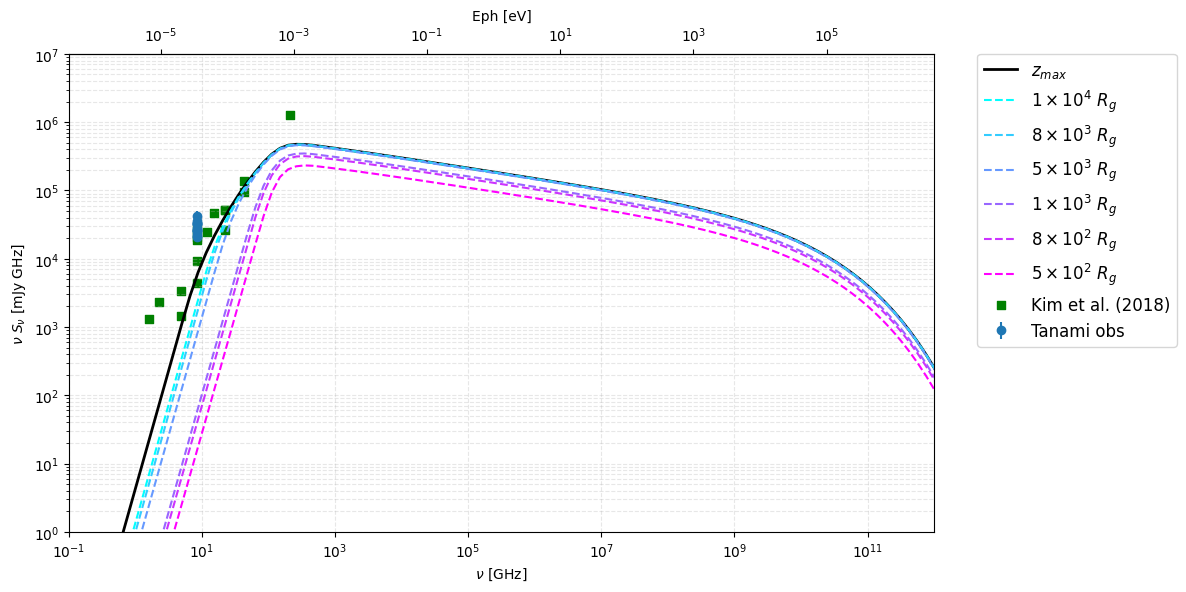

In [2]:
from matplotlib import cm

fig, axs = plt.subplots(1, 1, figsize=(12, 6))

# Read the data from Flux.dat
df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])
KIM_flux = pd.read_csv('Kim(2018)_CENA_OBS.csv', header=0)
# EHT1_flux = pd.read_csv('EHT_226.1918.csv', header=1)
# EHT2_flux = pd.read_csv('EHT_227.0707.csv', header=1)
# EHT3_flux = pd.read_csv('EHT_228.1918.csv', header=1)
EHT4_flux = pd.read_csv('EHT_229.0707.csv', header=1)
tanami_flux = pd.read_csv('TANAMI_cenA_obs.csv', header=0)
parkes_flux = pd.read_csv('parkes_cena_obs.csv', header=0)
MOST_flux = pd.read_csv('MOST_cena_obs.csv', header=0)
obs_flux = pd.read_csv('Meisenheimer2008.csv',sep=';',header=None)

def energy_to_freq(E_eV):
    h = 4.135667696e-15  # eV·s
    return E_eV / h/1e9

def freq_to_energy(nu):
    h = 4.135667696e-15  # eV·s
    return nu * h * 1e9

# # Parameters for reference line
# A = 2e31
# m = -1.15
# x = np.logspace(1, 12, 200)
# y = A * x**m
# axs.plot(x, y, label=f'y = {A:.0e} × x^{m}', color='crimson', linewidth=2, linestyle='-.')

# Define the columns to plot
flux_columns = [ 'Flujo_6', 'Flujo_5', 'Flujo_4', 'Flujo_3', 'Flujo_2', 'Flujo_1']
labels=[r'$1\times10^4~R_g$',r'$8\times10^3~R_g$',r'$5\times10^3~R_g$',r'$1\times10^3~R_g$',r'$8\times10^2~R_g$',r'$5\times10^2~R_g$']

# Get Viridis colormap
cmap = cm.get_cmap('cool', len(flux_columns))
colors = cmap(np.linspace(0, 1, len(flux_columns)))

axs.plot(
        df_flux9['nu']/1e9,#Frecuencia en GHz
        df_flux9['Flujo_Tot']*10**26*df_flux9['nu']/1e9,#Flujo x frecuencia, frecuencia en GHz, flujo en mJy
        label=r'$z_{max}$',
        linestyle='-',
        color='black',
        lw=2
    )
# Plot each curve with a Viridis color
for col, color, label in zip(flux_columns, colors, labels):
    axs.plot(
        df_flux9['nu']/1e9,#Frecuencia en GHz
        df_flux9[col]*10**26*df_flux9['nu']/1e9,#Flujo x frecuencia, frecuencia en GHz, flujo en mJy
        label=label,
        linestyle='--',
        color=color
    )

# axs.scatter(obs_flux[0]/1e9,obs_flux[1]*1e3/1e9, label='Meisenheimer2008',c='black')
axs.errorbar(tanami_flux['Frequency (Hz)']/1e9,tanami_flux['Flux']*1e3/1e9,yerr=tanami_flux['F Unc High']*1e3/1e9, fmt='o',label='Tanami obs')
# axs.scatter(EHT1_flux['Iamp(Jy)']/EHT1_flux['Iamp(Jy)']*226.1918,EHT1_flux['Iamp(Jy)']*1e3*226.1918,label='EHT obs')
# axs.scatter(EHT2_flux['Iamp(Jy)']/EHT2_flux['Iamp(Jy)']*227.0707,EHT2_flux['Iamp(Jy)']*1e3*227.0707,label='EHT2 obs')
# axs.scatter(EHT3_flux['Iamp(Jy)']/EHT3_flux['Iamp(Jy)']*228.1918,EHT3_flux['Iamp(Jy)']*1e3*228.1918,label='EHT3 obs')
# axs.scatter(EHT4_flux['Iamp(Jy)']/EHT4_flux['Iamp(Jy)']*229.0707,EHT4_flux['Iamp(Jy)']*1e3*229.0707,label='EHT obs', color='black')
axs.scatter(KIM_flux[' Frequency(GHz)'],KIM_flux[' FluxDensity(Jy)']*1e3*KIM_flux[' Frequency(GHz)'],label='Kim et al. (2018)', color='green', marker='s')
# axs.errorbar(MOST_flux['Frequency (Hz)']/1e9,MOST_flux['Flux']*1e3/1e9,yerr=MOST_flux['F Unc High']*1e3/1e9, fmt='o',label='MOST obs')
# axs.errorbar(Spitzer_flux['Frequency (Hz)']/1e9,Spitzer_flux['Flux']*1e3/1e9,yerr=Spitzer_flux['F Unc High']*1e3/1e9, fmt='o',label='Spitzer obs')
# axs.errorbar(Gemini_flux['Frequency (Hz)']/1e9,Gemini_flux['Flux']*1e3/1e9,yerr=Gemini_flux['F Unc High']*1e3/1e9, fmt='o',label='Gemini obs')
# axs.errorbar(suzaku_flux['Frequency (Hz)']/1e9,suzaku_flux['Flux']*1e3/1e9,yerr=suzaku_flux['F Unc High']*1e3/1e9, fmt='o',label='suzaku obs')
# axs.errorbar(IRAS_flux['Frequency (Hz)']/1e9,IRAS_flux['Flux']*1e3/1e9,yerr=IRAS_flux['F Unc High']*1e3/1e9, fmt='o',label='IRAS obs')
# axs.errorbar(CHANDRA_flux['Frequency (Hz)']/1e9,CHANDRA_flux['Flux']*1e3/1e9,yerr=CHANDRA_flux['F Unc High']*1e3/1e9, fmt='o',label='CHANDRA obs')
# Secondary X-axis (energy)
ax_top = axs.secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
ax_top.set_xlabel('Eph [eV]')

# Axis settings
axs.set_xlabel(r'$\nu$ [GHz]')
axs.set_ylabel(r'$\nu$ $S_{\nu}$ [mJy GHz]')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_ylim(1e0, 1e7)
axs.set_xlim(1e-1, 1e12)
axs.legend(fontsize=12, loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
axs.grid(True, which='both', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig(f'Gaussian_Convolved_Map(0).jpeg', dpi=450)
plt.show()


# Done

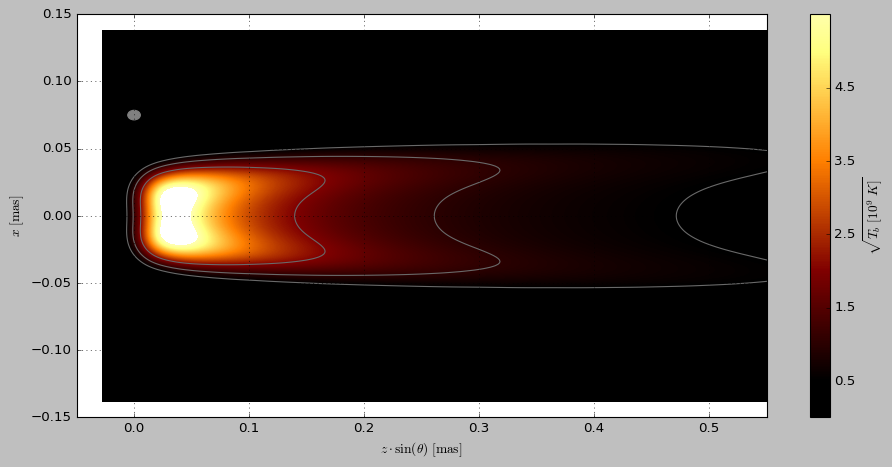

In [1294]:


with plt.style.context(('classic')):
    fig, axs = plt.subplots(1, 1, figsize=(12, 6))
    palette = plt.cm.afmhot
    ticks = [0.5,1.5,2.5,3.5, 4.5]
    norm = matplotlib.colors.Normalize(vmin=0.5, vmax=6.5)
    CS_conv = axs.contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,5.5 , 700))
    obs_cont = np.array([-1,-0.5,0,0.5,1,2])
    plot_cont = axs.contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])
    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    axs.add_patch(el)
    axs.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    axs.set_ylabel(r"$x~{\rm [mas]}$")
    axs.set_xlim([-0.05, 0.55])
    axs.set_ylim([-0.15, 0.15])
    axs.grid(alpha=1)
    plt.tight_layout()
    fig.colorbar(CS_conv, ax=axs, ticks=ticks, label=r'$\sqrt{T_b~[10^9~K]}$')
    plt.savefig('Mapa_Tb.jpeg', dpi=450)


In [194]:
flujo_x_altura = pd.read_csv('./../Code/dFlux_dz.dat', sep='\s+', header=0)
flujo_x_altura=flujo_x_altura.T
flujo_x_altura.columns = flujo_x_altura.iloc[0]      # asigna la primera fila como nombres
flujo_x_altura = flujo_x_altura.drop(flujo_x_altura.index[0])  # elimina esa primera fila

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_67685/1947292716.py:1: SyntaxWarning: invalid escape sequence '\s'
  flujo_x_altura = pd.read_csv('./../Code/dFlux_dz.dat', sep='\s+', header=0)


In [195]:
flujo_x_altura['columna_max'] = flujo_x_altura.idxmax(axis=1)
# flujo_x_altura['columna_max'] = flujo_x_altura.drop(columns='nu').idxmax(axis=1)
# flujo_x_altura


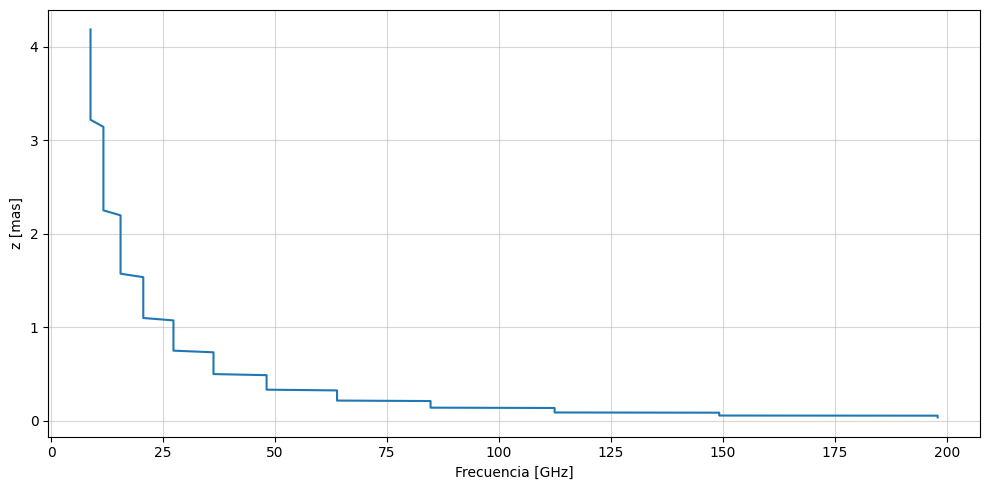

In [197]:
# 🔹 Graficar
ev2ghz=1/1e9/4.135667696e-15

plt.figure(figsize=(10, 5))
plt.plot(flujo_x_altura['columna_max'][:-1].astype(float)*ev2ghz,flujo_x_altura.index.astype(float)[:-1]*convert)
# plt.title("Valor del maximo de frecuencia en funcion de la altura en el jet")
plt.xlabel(r"Frecuencia [GHz]")
plt.ylabel("z [mas]")
# plt.xscale('log')
# plt.yscale('log')
# plt.ylim(2e9,2.5e11)
plt.grid(True, linestyle='-', alpha=0.5)
plt.tight_layout()
plt.savefig('Core_shift.jpeg', dpi=450)

plt.show()

In [185]:
# flujo_x_altura['nu'].astype(float)

In [184]:
# # 🔹 Graficar
# plt.figure(figsize=(10, 5))
# plt.plot(flujo_x_altura['columna_max'].astype(float)*convert,flujo_x_altura['nu'].astype(float)/1e9)
# plt.title("Valor del maximo de frecuencia en funcion de la altura en el jet")
# plt.ylabel(r"Frecuencia [GHz]")
# plt.xlabel("z [mas]")
# # plt.xscale('log')
# plt.yscale('log')
# # plt.ylim(2e9,2.5e11)
# plt.grid(True, linestyle='-', alpha=0.5)
# plt.tight_layout()
# plt.savefig('Core_shift.jpeg', dpi=450)

# plt.show()